# 149 · RL fine-tuning of a flow-matching policy (ReinFlow-lite): improve beyond the demonstrations with a success reward

In [1]:
import copy, numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from vlacourse.toy_envs import AroundObstacleEnv, collect_around

torch.manual_seed(0)
H, EXEC, NFE, SIGMA = 8, 4, 5, 0.08

def chunks(eps):
    X, Y = [], []
    for e in eps:
        T = len(e["act"])
        for t in range(T):
            X.append(e["obs"][t]); Y.append(e["act"][np.minimum(np.arange(t, t + H), T - 1)].reshape(-1))
    return torch.tensor(np.array(X)), torch.tensor(np.array(Y))

class Velocity(nn.Module):
    def __init__(self, h=256):
        super().__init__(); self.net = nn.Sequential(nn.Linear(4 + 2 * H + 1, h), nn.SiLU(), nn.Linear(h, h), nn.SiLU(), nn.Linear(h, 2 * H))
    def forward(self, o, x, tau):
        return self.net(torch.cat([o, x, tau], -1))

def fm_loss(v, X, Y, n=256):
    idx = torch.randint(0, len(X), (n,)); o, a1 = X[idx], Y[idx]; a0 = torch.randn_like(a1); tau = torch.rand(n, 1)
    return ((v(o, (1 - tau) * a0 + tau * a1, tau) - (a1 - a0)) ** 2).mean()

def chain(v, o, x0):
    x = x0
    for k in range(NFE):
        x = x + v(o, x, torch.full((len(o), 1), k / NFE)) / NFE
    return x

def episode(v, seed, stochastic):
    """Returns success and, for the stochastic policy, the summed log-probability of the executed chunks."""
    env = AroundObstacleEnv(); o = env.reset(seed=seed); done, logp, q = False, 0.0, []
    while not done:
        if not q:
            ot = torch.tensor(o)[None]; mean = chain(v, ot, torch.randn(1, 2 * H))
            if stochastic:
                a = (mean + SIGMA * torch.randn_like(mean)).detach()
                logp = logp + torch.distributions.Normal(mean, SIGMA).log_prob(a).sum()
            else:
                a = mean.detach()
            q = list(a.view(H, 2).numpy()[:EXEC])
        o, _, done, info = env.step(q.pop(0))
    return float(info["success"]), logp

def evaluate(v, n=60, seed=10_000):
    with torch.no_grad():
        return np.mean([episode(v, seed + i, False)[0] for i in range(n)])

In [2]:
X, Y = chunks(collect_around(30, seed=0))
pre = Velocity(); opt = torch.optim.Adam(pre.parameters(), 1e-3)
for _ in range(3000):
    loss = fm_loss(pre, X, Y); opt.zero_grad(); loss.backward(); opt.step()
base = evaluate(pre)
print(f"flow policy behavior-cloned from only 30 demos: success {base:.2f}")

flow policy behavior-cloned from only 30 demos: success 0.70


In [3]:
policy = copy.deepcopy(pre); opt = torch.optim.Adam(policy.parameters(), 3e-5)
baseline, curve, BC_W = base, [(0, base)], 0.5
for it in range(1, 41):
    batch = [episode(policy, 50_000 + it * 100 + k, True) for k in range(16)]
    R = torch.tensor([b[0] for b in batch]); logps = torch.stack([b[1] for b in batch])
    adv = R - baseline; baseline = 0.9 * baseline + 0.1 * R.mean().item()
    pg = -(adv * logps).mean() / 20
    loss = pg + BC_W * fm_loss(policy, X, Y)
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(policy.parameters(), 1.0); opt.step()
    if it % 5 == 0:
        curve.append((it, evaluate(policy, 40))); print(f"iteration {it:2d}: training success {R.mean():.2f}, deterministic eval {curve[-1][1]:.2f}")

iteration  5: training success 0.50, deterministic eval 0.78


iteration 10: training success 0.81, deterministic eval 0.82


iteration 15: training success 0.75, deterministic eval 0.72


iteration 20: training success 0.69, deterministic eval 0.72


iteration 25: training success 0.62, deterministic eval 0.55


iteration 30: training success 0.50, deterministic eval 0.70


iteration 35: training success 0.69, deterministic eval 0.70


iteration 40: training success 0.75, deterministic eval 0.72


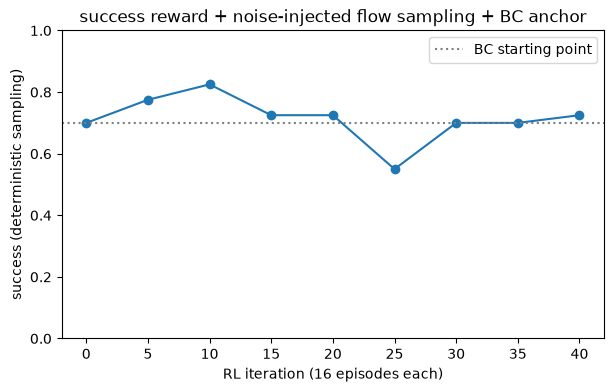

before RL 0.70 -> after RL 0.76 (100 episodes)


In [4]:
c = np.array(curve)
plt.figure(figsize=(7, 4)); plt.plot(c[:, 0], c[:, 1], "o-"); plt.axhline(base, c="gray", ls=":", label="BC starting point")
plt.xlabel("RL iteration (16 episodes each)"); plt.ylabel("success (deterministic sampling)"); plt.ylim(0, 1); plt.legend()
plt.title("success reward + noise-injected flow sampling + BC anchor"); plt.show()
print(f"before RL {base:.2f} -> after RL {evaluate(policy, 100):.2f} (100 episodes)")